In [20]:
import pandas as pd
import numpy as np
from pathlib import Path
import re
import unicodedata
import time
import pandas as pd

df = pd.read_parquet("../data/raw/np20ng_raw.parquet")

print(df.shape)
df.head()
required_columns = [
    "category", "source", "heading", "content"
]

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("\nData types:")
print(df[required_columns].dtypes)

print(
    "\nMemory:",
    round(df.memory_usage(deep=True).sum() / 1024**2, 2),
    "MB"
)

display(df[required_columns].head())

(231216, 4)
Shape: (231216, 4)
Columns: ['source', 'category', 'heading', 'content']

Data types:
category    str
source      str
heading     str
content     str
dtype: object

Memory: 1083.55 MB


,category,source,heading,content
0,Education,Gorkhapatra,"अटेर गर्दै कतिपय विद्यालय, चैतमै भर्ना अभियान ...","काठमाडौं,चैत्र ७ गते । उपत्याकाका कतिपय विद्या..."
1,Education,Gorkhapatra,"निर्वाचन प्रचारमा विद्यालय, शिक्षक र विद्यार्...","प्रकाश सिलवाल काठमाडौँ, चैत ६ गते । विगतका निर..."
2,Education,Gorkhapatra,विद्यार्थीलाई परम्परागत सीप सिकाउँदै विद्यालय,"अमरराज नहर्की तनहुँ, चैत्र ५ गते । तनहुँको एक ..."
3,Education,Gorkhapatra,आन्दोलन नगर्न शिक्षामन्त्रीको आग्रह,"गोरखापत्र समाचारदाता काठमाडौँ, चैत ३ गते । शिक..."
4,Education,Gorkhapatra,विश्वविद्यालयमा हडताल नगर्न शिक्षामन्त्रीको आग्रह,"काठमाडौं, चैत २ गते। शिक्षा विज्ञान तथा प्रविध..."


In [2]:
print("Missing values per column:")
print(df[required_columns].isna().sum())

content = df["content"].fillna("").astype(str)
heading = df["heading"].fillna("").astype(str)

print("\nEmpty content:", content.str.strip().eq("").sum())
print("Empty heading:", heading.str.strip().eq("").sum())
print("Missing category:", df["category"].isna().sum())
print("Missing source:", df["source"].isna().sum())

Missing values per column:
category     0
source       0
heading      2
content     25
dtype: int64

Empty content: 30
Empty heading: 2
Missing category: 0
Missing source: 0


In [3]:
category_counts = df["category"].value_counts(dropna=False)

category_summary = pd.DataFrame({
    "count": category_counts,
    "percentage": (
        df["category"]
        .value_counts(normalize=True, dropna=False)
        .mul(100)
        .round(2)
    )
})

display(category_summary)

print("Number of categories:", df["category"].nunique())
print("Largest category:", category_counts.max())
print("Smallest category:", category_counts.min())

,count,percentage
category,,
Politics,31021,13.42
Society,27802,12.02
Sports,24392,10.55
Economy,23653,10.23
Entertainment,22664,9.80
World,17431,7.54
Business,11645,5.04
Bank,10526,4.55
Health,9469,4.10


Number of categories: 20
Largest category: 31021
Smallest category: 1931


count    231216.000000
mean        272.193257
std         301.350736
min           0.000000
1%           43.000000
5%           66.000000
25%         116.000000
50%         177.000000
75%         307.000000
95%         786.000000
99%        1532.000000
max        8433.000000
Name: content, dtype: float64


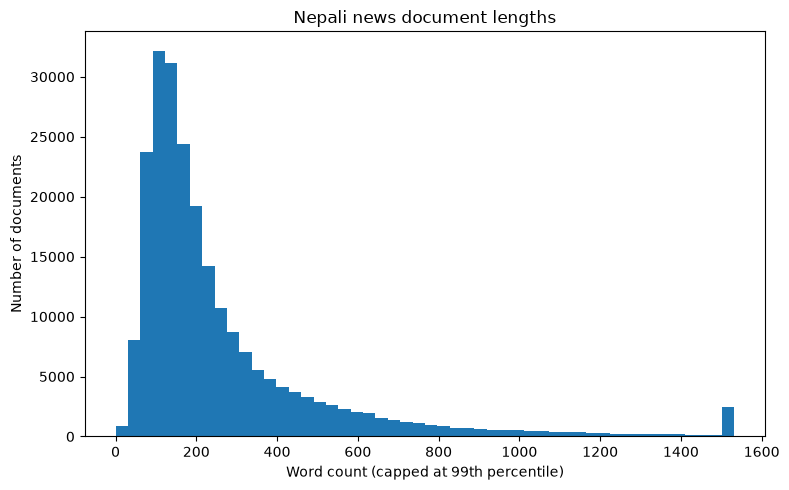

In [4]:
word_count = content.str.split().str.len()

print(word_count.describe(
    percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
))

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(word_count.clip(upper=word_count.quantile(0.99)), bins=50)
plt.xlabel("Word count (capped at 99th percentile)")
plt.ylabel("Number of documents")
plt.title("Nepali news document lengths")
plt.tight_layout()

Path("results/figures").mkdir(parents=True, exist_ok=True)
plt.savefig(
    "results/figures/document_lengths.png",
    dpi=150
)
plt.show()

In [5]:
audit_summary = pd.DataFrame({
    "metric": [
        "total_rows",
        "total_columns",
        "missing_category",
        "missing_source",
        "empty_content",
        "empty_heading",
        "num_categories",
        "num_sources",
        "median_word_count",
        "p95_word_count"
    ],
    "value": [
        len(df),
        len(df.columns),
        int(df["category"].isna().sum()),
        int(df["source"].isna().sum()),
        int(content.str.strip().eq("").sum()),
        int(heading.str.strip().eq("").sum()),
        int(df["category"].nunique()),
        int(df["source"].nunique()),
        float(word_count.median()),
        float(word_count.quantile(0.95))
    ]
})

Path("results/tables").mkdir(parents=True, exist_ok=True)

audit_summary.to_csv(
    "results/tables/dataset_audit.csv",
    index=False
)

display(audit_summary)

,metric,value
0,total_rows,231216.0
1,total_columns,4.0
2,missing_category,0.0
3,missing_source,0.0
4,empty_content,30.0
5,empty_heading,2.0
6,num_categories,20.0
7,num_sources,10.0
8,median_word_count,177.0
9,p95_word_count,786.0


In [22]:
def normalize_text(text):
    text = unicodedata.normalize("NFC", str(text))
    text = re.sub(r"\s+", " ", text).strip()
    return text

audit_df = df.copy()

audit_df["normalized_content"] = (
    audit_df["content"]
    .fillna("")
    .astype(str)
    .map(normalize_text)
)

valid_text = audit_df["normalized_content"].ne("")

In [7]:
duplicate_rows = audit_df[
    valid_text
    & audit_df["normalized_content"].duplicated(keep=False)
].copy()

duplicate_groups = (
    duplicate_rows.groupby("normalized_content")
    .agg(
        copies=("category", "size"),
        category_count=("category", "nunique"),
        source_count=("source", "nunique")
    )
    .sort_values("copies", ascending=False)
)

print("Rows in duplicate groups:", len(duplicate_rows))
print("Unique duplicate groups:", len(duplicate_groups))

print("\nGroups by number of distinct labels:")
print(duplicate_groups["category_count"].value_counts())

display(duplicate_groups.head(10))

Rows in duplicate groups: 601
Unique duplicate groups: 246

Groups by number of distinct labels:
category_count
1    232
2     14
Name: count, dtype: int64


,copies,category_count,source_count
normalized_content,,,
एजेन्सी,31,2,1
काठमाडौं,7,2,1
पोखरा,7,1,1
बेनी,7,1,1
"एजेन्सी । हिन्दूधर्म दर्शन तथा वस्तु शास्त्रले केही यस्ता व्यवस्था गरेका छन् जसको पालनले तपाईंको जीवन सहज र व्यवस्थित रुपमा अघि बढ्न सक्छन् । दीशा, बार, ग्रहआदीको हेक्का राखी गरिएका कामहरु सफल हुने दाबी ज्यातिषविज्ञान, वास्तुशास्त्रले गरेका छन् । केही महत्वपूर्ण वास्तु टिप्सहरु यस्ता छन् जसले तपाईंका कामलाई सफल पार्न भूमिका खेल्छन्",6,1,1
कञ्चनपुर,5,1,1
"एजेन्सी । बाँसलाई ‘घाँसको राजा पनि भन्ने गरिन्छ। बाँसको कलिलो भागलाई नै तामा भन्ने गरिन्छ। एसियामा यो प्रचलित सब्जी तामालाई हामी अचार वा सब्जीको रूपमा प्रयोग गर्दछौं। तामा एउटा स्वथ्यकर, पूर्ण र गुणकारी सब्जी हो",4,1,1
"एजेन्सी । भनिन्छ ग्यास्ट्रिक नेपालीको राष्ट्रिय रोग हो। धेरैको ग्यास्ट्रिक गुनासो सुन्न पाईन्छ हिजो आज । मानिस खान नपाएर भन्दा पनि खान नजानेर रोगी छ हिजो आज। अत्याधुनिक जीवनशैली, कम ब्यायाम, मीसावट युक्त अन्न, बिशादीपूर्ण तरकारी, जिब्रोले स्वाद माने अत्याधिक भोजन जस्ता स्वास्थ्य प्रतिकुल कृयाकलापले मानिस रोग बाट ग्रसित छ। मसालेदार, तारेभुटेको, चप्प खोज्ने हाम्रो स्वादे जिब्रोनै हाम्रो परम शत्रु बन्न पुगेको छ। नआतिनुहोस् यहाँ हामीले पाएको फाईदा यहाँहरु समक्ष् बाँड्दै छौँ। जुवानो र बिरे नुन त हामी सबैको भान्छामा हुने चिज हो। हो यही हो यो रोग को औषधी । जुवानो सुत्केरीलाई मात्र खुवाउने चिज होइन रहेछ। यो त पाचक रहेछ, त्यही भएर त्यो सुत्केरी अवस्थाको अत्यधिक चिल्लो पचाउने काम गर्दो रहेछ यसले। औषधी बनाउने बिधी यस्तो छ एकातिर बिरे नुनलाई धुलो हुने गरी पिसौं। ज्वानो ५ चम्चा जत्ती भुटौं र त्यो पनि पिसौं। ५ चम्चा ज्वानो मा करीब १ चम्चा बिरे नुन मिसाऔँ",4,1,1
काठमाडौँ,4,2,1


In [8]:
duplicate_groups.to_csv(
    "results/tables/duplicate_groups.csv"
)

In [9]:
conflicting_texts = duplicate_groups[
    duplicate_groups["category_count"] > 1
].index

conflicting_examples = audit_df[
    audit_df["normalized_content"].isin(conflicting_texts)
][["category", "source", "heading", "content"]]

display(conflicting_examples.head(30))

,category,source,heading,content
24797,Bank,Onlinekhabar,ट्राङ्लोबाट इसेवामनी ट्रान्सफरमार्फत नेपालमा र...,इसेवा सेवा मनी ट्रान्सफर र विश्वका अधिकांश देश...
24875,Bank,Onlinekhabar,सानिमा बैंकका ग्राहकले शून्य प्रतिशत किस्तामा ...,सानिमा बैंक लिमिटेड र नेपालस्थित सामसुङ मोबाइल...
27755,Economy,Nagarik,एनसेलको लोकल कल महसुल घट्यो,एनसेलका ग्राहकले अब अझै सस्तोमा नेपालभर एउटै क...
28279,Economy,Nagarik,सामसङले ल्यायो ग्यालेक्सी एस-२१ एफई ५जी,सामसङले सन् २०२२ को आफ्नो पहिलो स्मार्टफोन सार...
35646,Lifestyle,Nepalipatra,https://www.nepalipatra.comवास्तु टिप्स: जान्न...,एजेन्सी
35665,Lifestyle,Nepalipatra,https://www.nepalipatra.comवास्तुशास्त्र: पसल ...,एजेन्सी
35688,Lifestyle,Nepalipatra,https://www.nepalipatra.comवास्तु टिप्सः घरमा ...,एजेन्सी
35712,Lifestyle,Nepalipatra,https://www.nepalipatra.comब्लड प्रेसर लो भएमा...,एजेन्सी
35735,Lifestyle,Nepalipatra,https://www.nepalipatra.comवास्तुशास्त्र: घरको...,एजेन्सी
35802,Lifestyle,Nepalipatra,https://www.nepalipatra.comयस्ता व्यक्तिहरु सद...,एजेन्सी


In [23]:
audit_df = df.copy().reset_index(names="original_index")

audit_df["normalized_content"] = (
    audit_df["content"]
    .fillna("")
    .astype(str)
    .map(normalize_text)
)

missing_label = audit_df["category"].isna()
empty_text = audit_df["normalized_content"].eq("")

clean_df = audit_df.loc[
    ~(missing_label | empty_text)
].copy()

clean_df["category"] = clean_df["category"].astype(str)

print("Original rows:", len(audit_df))
print("Clean rows:", len(clean_df))
print("Removed rows:", len(audit_df) - len(clean_df))
print("Remaining categories:", clean_df["category"].nunique())

Original rows: 231216
Clean rows: 231186
Removed rows: 30
Remaining categories: 20


In [11]:
from sklearn.model_selection import StratifiedGroupKFold

X = clean_df["content"].fillna("").astype(str)
y = clean_df["category"]
groups = clean_df["normalized_content"]

outer_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_val_idx, test_idx = next(
    outer_cv.split(X, y, groups=groups)
)

X_remaining = X.iloc[train_val_idx]
y_remaining = y.iloc[train_val_idx]
groups_remaining = groups.iloc[train_val_idx]

inner_cv = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=43
)

train_rel_idx, val_rel_idx = next(
    inner_cv.split(
        X_remaining,
        y_remaining,
        groups=groups_remaining
    )
)

train_idx = train_val_idx[train_rel_idx]
val_idx = train_val_idx[val_rel_idx]

train_df = clean_df.iloc[train_idx].copy()
val_df = clean_df.iloc[val_idx].copy()
test_df = clean_df.iloc[test_idx].copy()

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 138711
Validation: 46237
Test: 46238


In [18]:
train_groups = set(train_df["normalized_content"])
val_groups = set(val_df["normalized_content"])
test_groups = set(test_df["normalized_content"])

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

print("Duplicate-group leakage check passed.")
all_labels = set(clean_df["category"].unique())

for name, part in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df)
]:
    present = set(part["category"].unique())
    print(
        name,
        "rows:", len(part),
        "categories:", len(present),
        "missing categories:", sorted(all_labels - present)
    )
from pathlib import Path

processed_dir = Path("data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

for name, part in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df)
]:
    part.to_parquet(processed_dir / f"{name}.parquet", index=False)

print("Partitions saved.")

Duplicate-group leakage check passed.
train rows: 138711 categories: 20 missing categories: []
validation rows: 46237 categories: 20 missing categories: []
test rows: 46238 categories: 20 missing categories: []
Partitions saved.


In [20]:
from pathlib import Path

processed_dir = Path("../data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

for name, part in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df)
]:
    part.to_parquet(processed_dir / f"{name}.parquet", index=False)

print("Partitions saved.")

Partitions saved.


In [8]:
#tf idf baseline

import time

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

train_df = pd.read_parquet("../data/processed/train.parquet")
test_df = pd.read_parquet("../data/processed/test.parquet")
val_df = pd.read_parquet("../data/processed/validation.parquet")

X_train = train_df["content"].fillna("").astype(str)
y_train = train_df["category"]

X_val = val_df["content"].fillna("").astype(str)
y_val = val_df["category"]

vectorizer_uni = TfidfVectorizer(
    ngram_range=(1, 1),
    min_df=2,
    max_features=300_000,
    sublinear_tf=True
)

start = time.perf_counter()

X_train_uni = vectorizer_uni.fit_transform(X_train)
X_val_uni = vectorizer_uni.transform(X_val)

uni_vectorize_time = time.perf_counter() - start

lr_uni = LogisticRegression(
    max_iter=1000,
    C=1.0
)

start = time.perf_counter()
lr_uni.fit(X_train_uni, y_train)
uni_fit_time = time.perf_counter() - start

uni_pred = lr_uni.predict(X_val_uni)

print("Accuracy:", accuracy_score(y_val, uni_pred))
print("Macro-F1:", f1_score(y_val, uni_pred, average="macro"))
print("Weighted-F1:", f1_score(y_val, uni_pred, average="weighted"))
print("Features:", X_train_uni.shape[1])
print("Vectorization time:", round(uni_vectorize_time, 2), "s")
print("Fit time:", round(uni_fit_time, 2), "s")

Accuracy: 0.7428682656746761
Macro-F1: 0.7028342387553842
Weighted-F1: 0.7396432075300241
Features: 32113
Vectorization time: 73.53 s
Fit time: 135.02 s


In [10]:
import pandas as pd
import time

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
train_df = pd.read_parquet("../data/processed/train.parquet")
test_df = pd.read_parquet("../data/processed/test.parquet")
val_df = pd.read_parquet("../data/processed/validation.parquet")

X_train = train_df["content"].fillna("").astype(str)
y_train = train_df["category"]

X_val = val_df["content"].fillna("").astype(str)
y_val = val_df["category"]
vectorizer_bi = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_features=300_000,
    sublinear_tf=True
)

start = time.perf_counter()

X_train_bi = vectorizer_bi.fit_transform(X_train)
X_val_bi = vectorizer_bi.transform(X_val)

bi_vectorize_time = time.perf_counter() - start

lr_bi = LogisticRegression(
    max_iter=1000,
    C=1.0
)

start = time.perf_counter()
lr_bi.fit(X_train_bi, y_train)
bi_fit_time = time.perf_counter() - start

bi_pred = lr_bi.predict(X_val_bi)

print("Accuracy:", accuracy_score(y_val, bi_pred))
print("Macro-F1:", f1_score(y_val, bi_pred, average="macro"))
print("Weighted-F1:", f1_score(y_val, bi_pred, average="weighted"))
print("Features:", X_train_bi.shape[1])
print("Vectorization time:", round(bi_vectorize_time, 2), "s")
print("Fit time:", round(bi_fit_time, 2), "s")

Accuracy: 0.7678482600514739
Macro-F1: 0.7242795173848491
Weighted-F1: 0.7639071438320815
Features: 300000
Vectorization time: 144.95 s
Fit time: 1090.16 s


In [11]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(C=1.0)

start = time.perf_counter()
svm_model.fit(X_train_bi, y_train)
svm_fit_time = time.perf_counter() - start

svm_pred = svm_model.predict(X_val_bi)

print("Accuracy:", accuracy_score(y_val, svm_pred))
print("Macro-F1:", f1_score(y_val, svm_pred, average="macro"))
print("Weighted-F1:", f1_score(y_val, svm_pred, average="weighted"))
print("Fit time:", round(svm_fit_time, 2), "s")

Accuracy: 0.7867508705149555
Macro-F1: 0.7516168975147549
Weighted-F1: 0.7837787427283218
Fit time: 68.01 s


In [13]:
results = []

def record_result(name, y_true, y_pred, vectorize_seconds, fit_seconds, features):
    results.append({
        "experiment": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted"),
        "vectorize_seconds": vectorize_seconds,
        "fit_seconds": fit_seconds,
        "n_features": features
    })

record_result(
    "unigram_logistic_regression",
    y_val, uni_pred,
    uni_vectorize_time, uni_fit_time,
    X_train_uni.shape[1]
)

record_result(
    "bigram_logistic_regression",
    y_val, bi_pred,
    bi_vectorize_time, bi_fit_time,
    X_train_bi.shape[1]
)

record_result(
    "bigram_linear_svm",
    y_val, svm_pred,
    bi_vectorize_time, svm_fit_time,
    X_train_bi.shape[1]
)

results_df = pd.DataFrame(results)

display(
    results_df.sort_values("macro_f1", ascending=False)
)

results_df.to_csv(
    "../results/tables/baseline_comparison.csv",
    index=False
)

,experiment,accuracy,macro_f1,weighted_f1,vectorize_seconds,fit_seconds,n_features
2,bigram_linear_svm,0.786751,0.751617,0.783779,144.95219,68.011135,300000
1,bigram_logistic_regression,0.767848,0.724280,0.763907,144.95219,1090.158470,300000
0,unigram_logistic_regression,0.742868,0.702834,0.739643,73.53369,135.024707,32113


In [31]:
from sklearn.metrics import classification_report

# Generate predictions using the trained bigram Linear SVM
svm_pred = svm_model.predict(X_val_bi)

print(classification_report(
    y_val,
    svm_pred,
    zero_division=0
))

               precision    recall  f1-score   support

         Arts       0.72      0.60      0.65      1542
   Automobile       0.78      0.81      0.80      1030
         Bank       0.78      0.82      0.80      2105
     Business       0.63      0.50      0.56      2329
        Crime       0.79      0.79      0.79      1635
      Economy       0.63      0.62      0.63      4731
    Education       0.78      0.81      0.80       742
   Employment       0.68      0.59      0.63       386
Entertainment       0.85      0.91      0.88      4533
       Health       0.74      0.72      0.73      1893
    Lifestyle       0.80      0.78      0.79       771
   Literature       0.70      0.67      0.68       830
       Market       0.72      0.62      0.67       874
      Opinion       0.84      0.81      0.82       789
     Politics       0.86      0.90      0.88      6205
      Society       0.72      0.73      0.72      5560
       Sports       0.98      0.99      0.98      4879
   Techno

In [32]:
import pandas as pd

error_df = val_df[
    ["category", "source", "heading", "content"]
].copy()

# Convert predictions to an array to preserve row order
error_df["predicted_category"] = svm_pred

wrong_predictions = error_df[
    error_df["category"] != error_df["predicted_category"]
].copy()

print("Incorrect predictions:", len(wrong_predictions))
print("Validation examples:", len(val_df))
print(
    "Error rate:",
    round(len(wrong_predictions) / len(val_df), 4)
)

display(
    wrong_predictions[
        [
            "category",
            "predicted_category",
            "source",
            "heading",
            "content"
        ]
    ].head(20)
)

Incorrect predictions: 9860
Validation examples: 46237
Error rate: 0.2132


,category,predicted_category,source,heading,content
0,Education,Politics,Gorkhapatra,एन प्याब्सनको अध्यक्षमा न्यौपानेको उम्मेदवारी ...,"सिराज खान नेपालगञ्ज, फागुन २३ गते । निजी विद्य..."
11,Education,Society,Gorkhapatra,सगरमाथा इन्जिनीयरिङ कलेज र र ‘इयुटी प्लस एलायन...,"काठमाडौँ, पुस २६ गते । सगरमाथा इन्जिनियरिङ कले..."
14,Education,Society,Gorkhapatra,"विद्यार्थीलाई खोपको आस, नपाउँदा त्रास","सरोज ढुङ्गेल काठमाडौँ, पुस १६ गते । भक्तपुर दध..."
15,Education,Health,Gorkhapatra,गुल्मीमा २७ हजार विद्यार्थीलाई कोरोनाविरुद्धको...,"तिलाचन पाण्डेतम्घास, पुस ११ गते । गुल्मीमा २७ ..."
29,Education,Politics,Gorkhapatra,बागमती प्रदेश सरकारले ११९ विद्यार्थीलाई प्रावि...,"मकवानपुर, कात्तिक १२ गते । बागमती प्रदेश सरकार..."
30,Education,Politics,Gorkhapatra,"प्रदेश मन्त्रिपरिषद् बैठक, प्रदेशका प्रत्येक स...","राममणि दाहालहेटौँडा, कात्तिक ११ गते । बागमती प..."
48,Education,Economy,Gorkhapatra,प्राज्ञिक शोध गर्नेलाई केन्द्रीय बैंकले शोधवृत...,"काठमाडौँ, भदौ २ गते । नेपाल राष्ट्र बैंकले प्र..."
55,Education,Crime,Gorkhapatra,नक्कली परीक्षार्थी पक्राउ,"डोटी, साउन १६ गते । अर्काको नाममा मौखिक परीक्ष..."
57,Education,Lifestyle,Gorkhapatra,गुरुप्रति आस्था प्रकट गर्दै मनाइयो गुरु पूर्णिमा,"पूर्णप्रसाद मिश्र काठमाडौँ, साउन ९ गते ।आषाढ ..."
67,Education,Health,Gorkhapatra,कोरोना कहर : नेपालगञ्जका विद्यालय एक साता बन्द,"राँझा, वैशाख २ गते । कोरोना भाइरस सङ्क्रमण बढे..."


In [34]:
from pathlib import Path

Path("../results/tables").mkdir(
    parents=True,
    exist_ok=True
)

wrong_predictions.to_csv(
    "../results/tables/day2_svm_errors.csv",
    index=False,
    encoding="utf-8-sig"
)

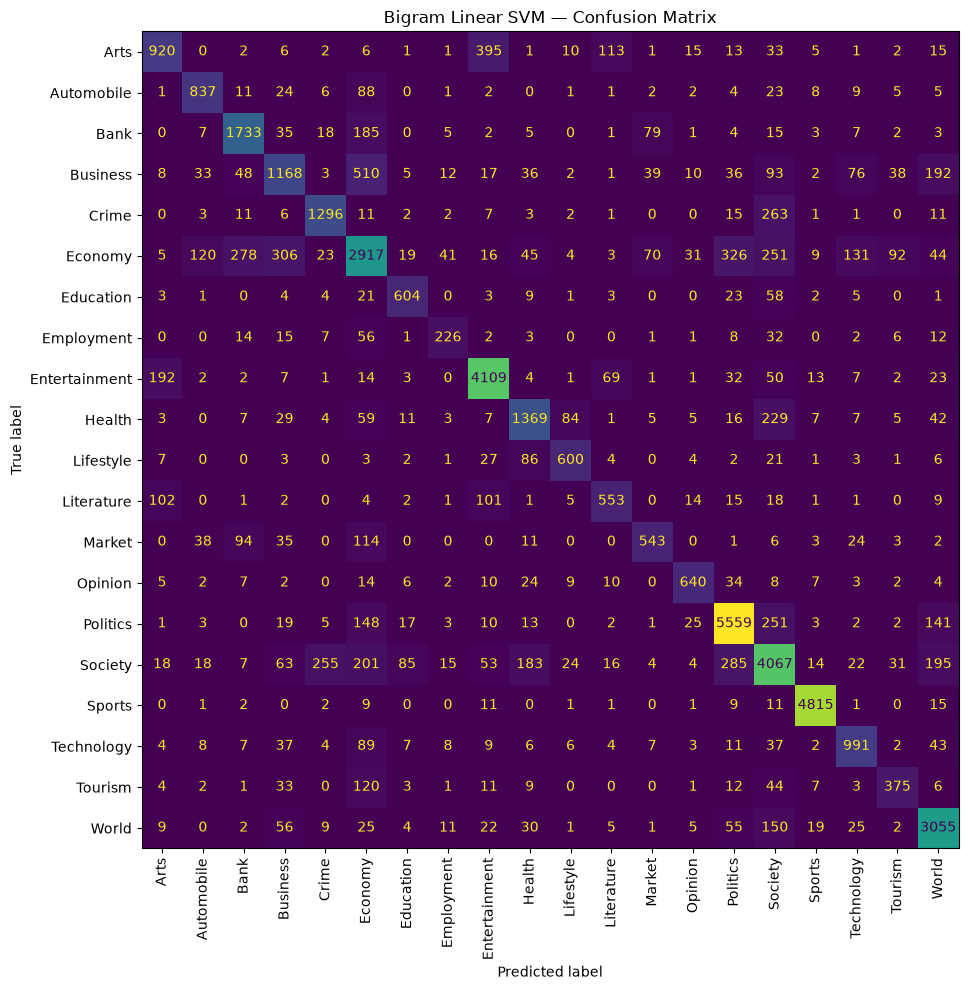

In [36]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from pathlib import Path

labels = sorted(y_train.unique())

cm = confusion_matrix(
    y_val,
    svm_pred,
    labels=labels
)

Path("../results/figures").mkdir(
    parents=True,
    exist_ok=True
)

fig, ax = plt.subplots(figsize=(12, 10))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
).plot(
    ax=ax,
    xticks_rotation=90,
    colorbar=False
)

plt.title("Bigram Linear SVM — Confusion Matrix")
plt.tight_layout()

plt.savefig(
    "../results/figures/confusion_matrix_day2.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [37]:
confusions = (
    wrong_predictions
    .groupby(["category", "predicted_category"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

display(confusions.head(15))

,category,predicted_category,count
55,Business,Economy,510
6,Arts,Entertainment,395
98,Economy,Politics,326
88,Economy,Business,306
257,Society,Politics,285
87,Economy,Bank,278
81,Crime,Society,263
247,Society,Crime,255
238,Politics,Society,251
99,Economy,Society,251


In [39]:
import numpy as np

# Decision scores for all validation examples
decision_scores = svm_model.decision_function(X_val_bi)

# The predicted class is the class with the highest decision score
predicted_index = decision_scores.argmax(axis=1)

# Highest score and second-highest score for each example
sorted_scores = np.sort(decision_scores, axis=1)

top_score = sorted_scores[:, -1]
second_score = sorted_scores[:, -2]

# Difference between the top two scores
score_margin = top_score - second_score

confidence_df = val_df[
    ["category", "source", "heading", "content"]
].copy().reset_index(drop=True)

confidence_df["predicted_category"] = svm_pred
confidence_df["top_decision_score"] = top_score
confidence_df["score_margin"] = score_margin

confidence_df["correct"] = (
    confidence_df["category"]
    == confidence_df["predicted_category"]
)

wrong_confident = confidence_df[
    ~confidence_df["correct"]
].sort_values(
    "score_margin",
    ascending=False
)

display(
    wrong_confident[
        [
            "category",
            "predicted_category",
            "source",
            "heading",
            "top_decision_score",
            "score_margin"
        ]
    ].head(10)
)

,category,predicted_category,source,heading,top_decision_score,score_margin
27382,Economy,Politics,Nepalkhabar,जसपा सुदूरपश्चिम प्रदेश संसदीय दलका नेता चौधरी...,2.476218,3.687840
28633,Economy,Politics,Aarthiknews,एमाले महाधिवेशनः १५ करोडभन्दा बढीको व्यापार हुने,2.048021,3.280061
25759,Economy,Politics,Nepalkhabar,"शोधनान्तर घाटाका जन्मदाता ओली र खतिवडा, गठबन्ध...",1.908378,3.193499
39331,Automobile,Technology,Setopati,१८ वाट फास्ट चार्जिङ सुविधा भएको ओपो फोन,2.199842,3.140496
4196,Society,Politics,Nepalkhabar,महाअभियोगको प्रतिवाद गर्ने निर्णय गरेको एमाले ...,1.578558,2.920777
26007,Economy,Automobile,Nepalkhabar,टाटा टियागोले पार गर्‍यो चार लाखवटा बिक्रीको क...,1.779576,2.916675
19931,Society,Politics,Nepalkhabar,दिल्लीमा प्रधानमन्त्रीपत्नी आरजुको पाठेघरको शल...,1.509999,2.901303
40158,Arts,Entertainment,Setopati,'अब संस्कृति जोगाउने सिनेमा बन्नुपर्छ',1.940197,2.821029
28560,Economy,Politics,Aarthiknews,एमाले सरकारका उपलब्धिलाई जनतामा लान अध्यक्ष ओल...,1.713429,2.816221
4070,Society,Politics,Nepalkhabar,कांग्रेसको सर्लाही अधिवेशन : नेतृत्व चयनका लाग...,1.661866,2.734529


In [40]:
source_counts = clean_df["source"].value_counts()

print("Number of sources:", clean_df["source"].nunique())

display(
    source_counts.head(20).to_frame("documents")
)

source_category = pd.crosstab(
    clean_df["source"],
    clean_df["category"]
)

display(source_category.head(20))

Number of sources: 10


,documents
source,
Nepalkhabar,69504
Onlinekhabar,66716
Ekantipur,29875
Aarthiknews,25965
Setopati,15541
Nagarik,11106
Gorkhapatra,5059
Crimenews,3920
Nepalipatra,1952


category,Arts,Automobile,Bank,Business,Crime,Economy,Education,Employment,Entertainment,Health,Lifestyle,Literature,Market,Opinion,Politics,Society,Sports,Technology,Tourism,World
source,,,,,,,,,,,,,,,,,,,,
Aarthiknews,0,900,7638,4706,0,5247,0,429,0,4442,0,0,2603,0,0,0,0,0,0,0
Crimenews,0,0,0,0,3920,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Educationpati,0,0,0,0,0,0,1548,0,0,0,0,0,0,0,0,0,0,0,0,0
Ekantipur,0,0,0,3390,0,0,0,0,3592,1433,71,2627,1537,2405,0,0,6655,1129,0,7036
Gorkhapatra,0,0,0,0,0,1037,806,0,504,825,0,0,0,409,0,306,523,0,649,0
Nagarik,2559,0,0,0,0,2207,1355,0,0,0,0,0,0,0,2136,2112,0,737,0,0
Nepalipatra,0,0,0,0,0,0,0,0,0,0,1405,0,0,0,0,0,0,0,547,0
Nepalkhabar,0,739,0,0,225,14010,0,0,2926,0,53,31,0,0,22847,25382,0,726,0,2565
Onlinekhabar,0,1534,2888,0,4027,0,0,846,15642,2227,2327,1491,233,1131,6038,0,17214,1477,1811,7830


In [41]:
source_category_counts = pd.crosstab(
    clean_df["source"],
    clean_df["category"]
)

source_summary = pd.DataFrame({
    "documents": source_category_counts.sum(axis=1),
    "categories": (source_category_counts > 0).sum(axis=1)
}).sort_values(
    "documents",
    ascending=False
)

display(source_summary.head(30))

,documents,categories
source,,
Nepalkhabar,69504,10
Onlinekhabar,66716,15
Ekantipur,29875,10
Aarthiknews,25965,7
Setopati,15541,8
Nagarik,11106,6
Gorkhapatra,5059,8
Crimenews,3920,1
Nepalipatra,1952,2


In [42]:
import json
from pathlib import Path

config = {
    "dataset": "Suyogyart/np20ng",
    "target_column": "category",
    "text_column": "content",
    "random_seed": 42,
    "split_strategy": "StratifiedGroupKFold",
    "primary_metric": "macro_f1",
    "secondary_metrics": [
        "accuracy",
        "weighted_f1"
    ],
    "model": "LinearSVC",
    "model_experiment": "bigram_linear_svm",
    "svm": {
        "C": 1.0
    },
    "tfidf": {
        "ngram_range": [1, 2],
        "min_df": 2,
        "max_features": 300000,
        "sublinear_tf": True
    }
}

Path("notes").mkdir(
    parents=True,
    exist_ok=True
)

with open(
    "../notes/day2_experiment_config.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(config, f, indent=2)